In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import pyreadstat
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.stats import chi2_contingency, norm
import warnings, os, gc
warnings.filterwarnings('ignore')

gc.collect()

plt.rcParams['font.family']  = 'DejaVu Sans'
plt.rcParams['figure.dpi']   = 300
plt.rcParams['savefig.dpi']  = 300
plt.rcParams['savefig.bbox'] = 'tight'

print("Libraries loaded. Memory cleared.")


Libraries loaded. Memory cleared.


In [2]:
# User must specify path to NDHS Birth Recode file
data_path = "path/to/your/NDHS_BR_file.dta"  # Replace with actual file path
# Load only the 15 columns we need — not all 500+
cols_needed = [
'b0','b3','b4','b5','b7','b11','bord',
'v011','v024','v025','v106','v190',
'v501','v005','v021'
]

df_raw, meta = pyreadstat.read_dta(
    data_path,
    apply_value_formats=False,
    usecols=cols_needed
)

print(f"Loaded: {df_raw.shape[0]:,} rows, {df_raw.shape[1]} columns")
print(df_raw.head(3).to_string())


Loaded: 104,557 rows, 15 columns
     v005  v011  v021  v024  v025  v106  v190  v501  bord  b0    b3  b4  b5   b7 b11
0  491963  1062     1     1     1     0     2     4     5   0  1479   2   1  NaN  70
1  491963  1062     1     1     1     0     2     4     4   0  1409   1   1  NaN  21
2  491963  1062     1     1     1     0     2     4     3   0  1388   1   1  NaN  49


In [3]:
#We replaced DHS missing value codes

df = df_raw.copy()
df = df.where(~df.isin([8, 9, 98, 99, 998, 999, 9998, 9999]))

print("Missing codes replaced with NaN.")
print("Missing value counts:")
for v in cols_needed:
    n = df[v].isna().sum()
    print(f"  {v:<6}: {n:,}  ({n/len(df)*100:.1f}%)")


Missing codes replaced with NaN.
Missing value counts:
  b0    : 0  (0.0%)
  b3    : 0  (0.0%)
  b4    : 0  (0.0%)
  b5    : 0  (0.0%)
  b7    : 93,514  (89.4%)
  b11   : 27,395  (26.2%)
  bord  : 4,057  (3.9%)
  v011  : 884  (0.8%)
  v024  : 0  (0.0%)
  v025  : 0  (0.0%)
  v106  : 0  (0.0%)
  v190  : 0  (0.0%)
  v501  : 0  (0.0%)
  v005  : 0  (0.0%)
  v021  : 414  (0.4%)


In [4]:
# Building all analysis variables. All vectorised — no .apply() loops.

# --- Outcome: neonatal death ---
df['neonatal_death'] = np.where((df['b5'] == 0) & (df['b7'] == 0), 1, 0)
df.loc[df['b5'].isna(), 'neonatal_death'] = np.nan

# --- Singleton flag ---
df['is_singleton'] = ((df['b0'] == 0) | df['b0'].isna()).astype(int)

# --- Survey weight ---
df['survey_weight'] = df['v005'] / 1_000_000

# --- Maternal age at BIRTH (v011 and b3, not v012) ---
df['age_at_birth_yrs'] = (df['b3'] - df['v011']) / 12
df.loc[(df['age_at_birth_yrs'] < 12) | (df['age_at_birth_yrs'] > 55), 'age_at_birth_yrs'] = np.nan

df['maternal_age_grp'] = pd.cut(
    df['age_at_birth_yrs'],
    bins=[0, 20, 25, 30, 35, 40, 56],
    labels=['15-19', '20-24', '25-29', '30-34', '35-39', '40-49'],
    right=False
)
df['maternal_age_grp'] = pd.Categorical(
    df['maternal_age_grp'],
    categories=['15-19', '20-24', '25-29', '30-34', '35-39', '40-49'],
    ordered=True
)

# --- Geopolitical zone ---
df['geo_zone'] = df['v024'].map({
    1: 'North Central', 2: 'North East', 3: 'North West',
    4: 'South East', 5: 'South South', 6: 'South West'
})
df['geo_zone'] = pd.Categorical(
    df['geo_zone'],
    categories=['South West', 'South South', 'South East',
                'North Central', 'North East', 'North West']
)

# --- Residence ---
df['residence'] = df['v025'].map({1: 'Urban', 2: 'Rural'})

# --- Education ---
df['education'] = df['v106'].map({
    0: 'No education', 1: 'Primary', 2: 'Secondary', 3: 'Higher'
})
df['education'] = pd.Categorical(
    df['education'],
    categories=['Higher', 'Secondary', 'Primary', 'No education'],
    ordered=True
)

# --- Wealth ---
df['wealth'] = df['v190'].map({
    1: 'Poorest', 2: 'Poorer', 3: 'Middle', 4: 'Richer', 5: 'Richest'
})
df['wealth'] = pd.Categorical(
    df['wealth'],
    categories=['Richest', 'Richer', 'Middle', 'Poorer', 'Poorest'],
    ordered=True
)

# --- Child sex ---
df['child_sex'] = df['b4'].map({1: 'Male', 2: 'Female'})

# --- Birth order ---
conditions_bo = [
    df['bord'].isna(),
    df['bord'] == 1,
    df['bord'] <= 3,
    df['bord'] > 3
]
choices_bo = ['Missing', '1st birth', '2nd-3rd birth', '4th or higher birth']
df['birth_order_cat'] = np.select(conditions_bo, choices_bo, default='Missing')
df['birth_order_cat'] = pd.Categorical(
    df['birth_order_cat'],
    categories=['1st birth', '2nd-3rd birth', '4th or higher birth', 'Missing']
)

# --- Birth interval ---
conditions_bi = [
    df['bord'] == 1,
    df['b11'] < 18,
    df['b11'] < 24,
    df['b11'] < 36,
    df['b11'] >= 36
]
choices_bi = ['First birth', '<18 months', '18-23 months', '24-35 months', '36+ months']
df['birth_interval_cat'] = np.select(conditions_bi, choices_bi, default='unknown_bi')
df['birth_interval_cat'] = df['birth_interval_cat'].replace('unknown_bi', np.nan)
df['birth_interval_cat'] = pd.Categorical(
    df['birth_interval_cat'],
    categories=['36+ months', '24-35 months', '18-23 months', '<18 months', 'First birth']
)

# --- Marital status ---
df['marital_status'] = np.where(
    df['v501'].isin([1, 2]), 'Currently married/in union',
    np.where(df['v501'].isna(), 'unknown_ms', 'Not in union')
)
df['marital_status'] = df['marital_status'].replace('unknown_ms', np.nan)

# Validation check
print("Maternal age at BIRTH distribution (should peak at 20-34):")
print(df['maternal_age_grp'].value_counts().sort_index())
print()
print("Birth interval distribution:")
print(df['birth_interval_cat'].value_counts())

Maternal age at BIRTH distribution (should peak at 20-34):
maternal_age_grp
15-19    19165
20-24    30275
25-29    26821
30-34    17412
35-39     7782
40-49     2215
Name: count, dtype: int64

Birth interval distribution:
birth_interval_cat
24-35 months    28120
First birth     26397
36+ months      26071
18-23 months    14832
<18 months       8139
Name: count, dtype: int64


In [5]:
# Applying exclusion criteria and define samples
n_raw        = len(df)
df_analysis  = df[(df['b5'].notna()) & (df['is_singleton']==1)]

print(f"Raw records          : {n_raw:,}")
print(f"After filters        : {len(df_analysis):,}  "
      f"(removed {n_raw-len(df_analysis):,})")

# Regression sample — v023 NOT included in dropna (it is not used in the model)
cc_vars = [
'neonatal_death','wealth','education','residence','geo_zone',
'child_sex','birth_interval_cat','maternal_age_grp',
'marital_status','survey_weight','v021'
]
df_cc = df_analysis[cc_vars].dropna()
print(f"Descriptive sample   : {len(df_analysis):,}  (Tables 1-3)")
print(f"Regression sample    : {len(df_cc):,}  (Tables 4-5, "
      f"excluded {len(df_analysis)-len(df_cc):,})")

wd = (df_analysis['neonatal_death'] * df_analysis['survey_weight']).sum()
wb = df_analysis['survey_weight'].sum()
print(f"National weighted NMR: {wd/wb*1000:.1f} per 1,000 live births")

gc.collect()
print("Memory freed.")


Raw records          : 104,557
After filters        : 101,156  (removed 3,401)
Descriptive sample   : 101,156  (Tables 1-3)
Regression sample    : 99,271  (Tables 4-5, excluded 1,885)
National weighted NMR: 32.6 per 1,000 live births
Memory freed.


In [6]:
# Defining survey design functions

def run_survey_logit(formula, data, wt='survey_weight', psu='v021'):
    model = smf.glm(formula, data=data,
                    family=sm.families.Binomial(),
                    var_weights=data[wt])
    return model.fit(cov_type='cluster',
                     cov_kwds={'groups': data[psu]},
                     disp=False)

def get_or_rows(result, var, cats, ref):
    rows = []
    z = norm.ppf(0.975)
    for cat in cats:
        if cat == ref:
            rows.append({'Category':f'  {cat} (ref)',
'OR':'1.00','CI_95':'Reference','p':''})
        else:
            pname = next((p for p in result.params.index if f'[T.{cat}]' in p), None)
            if pname:
                b  = result.params[pname]
                se = result.bse[pname]
                pv = result.pvalues[pname]
                lo, hi = np.exp(b-z*se), np.exp(b+z*se)
                ps = ('<0.001' if pv<0.001 else '<0.01' if pv<0.01
                      else '<0.05' if pv<0.05 else f'{pv:.3f}')
                rows.append({'Category':f'  {cat}',
'OR':f'{np.exp(b):.2f}',
'CI_95':f'{lo:.2f}-{hi:.2f}','p':ps})
            else:
                rows.append({'Category':f'  {cat}',
'OR':'N/A','CI_95':'N/A','p':'N/A'})
    return rows

print("Survey design functions ready.")
print("  Weights : v005 / 1,000,000")
print("  Cluster : v021 (PSU)")


Survey design functions ready.
  Weights : v005 / 1,000,000
  Cluster : v021 (PSU)


In [7]:
# Table 1: sample profile and NMR per 1,000 births for each subgroup.
# Weighted % reflects the Nigerian population, not just the sampling frame.

def t1_row(data, col, cat, label):
    sub  = data[data[col]==cat]
    wall = data['survey_weight'].sum()
    wsub = sub['survey_weight'].sum()
    wd   = (sub['neonatal_death'] * sub['survey_weight']).sum()
    return {
'Characteristic': label,
'n (unweighted)': f"{len(sub):,}",
'Weighted %'    : f"{wsub/wall*100:.1f}",
'NMR per 1,000' : f"{wd/wsub*1000:.1f}" if wsub>0 else 'N/A'
    }

rows = []
wd = (df_analysis['neonatal_death']*df_analysis['survey_weight']).sum()
wb = df_analysis['survey_weight'].sum()
rows.append({'Characteristic':f'Total (n={len(df_analysis):,})',
'n (unweighted)':f'{len(df_analysis):,}',
'Weighted %':'100.0',
'NMR per 1,000':f'{wd/wb*1000:.1f}'})

blocks = [
    ('maternal_age_grp',  ['15-19','20-24','25-29','30-34','35-39','40-49'],
'Maternal age at birth'),
    ('marital_status',    ['Currently married/in union','Not in union'],
'Marital status'),
    ('residence',         ['Urban','Rural'],
'Place of residence'),
    ('geo_zone',          ['South West','South South','South East',
'North Central','North East','North West'],
'Geopolitical zone'),
    ('education',         ['Higher','Secondary','Primary','No education'],
'Maternal education'),
    ('wealth',            ['Richest','Richer','Middle','Poorer','Poorest'],
'Household wealth index'),
    ('child_sex',         ['Female','Male'],
'Sex of child'),
    ('birth_order_cat',   ['1st birth','2nd-3rd birth',
'4th or higher birth','Missing'],
'Birth order'),
    ('birth_interval_cat',['36+ months','24-35 months','18-23 months',
'<18 months','First birth'],
'Preceding birth interval'),
]

for col, cats, header in blocks:
    rows.append({'Characteristic':header,
'n (unweighted)':'','Weighted %':'','NMR per 1,000':''})
    for cat in cats:
        rows.append(t1_row(df_analysis, col, cat, f'  {cat}'))

table1 = pd.DataFrame(rows)
print("TABLE 1")
print(table1.to_string(index=False))
table1.to_csv("Table1_sociodemographic.csv", index=False)
print("Saved: Table1_sociodemographic.csv")


TABLE 1
              Characteristic n (unweighted) Weighted % NMR per 1,000
           Total (n=101,156)        101,156      100.0          32.6
       Maternal age at birth                                        
                       15-19         18,787       19.2          47.0
                       20-24         29,464       29.3          30.7
                       25-29         25,855       25.1          26.7
                       30-34         16,666       16.1          25.8
                       35-39          7,414        7.1          35.2
                       40-49          2,119        2.1          44.0
              Marital status                                        
  Currently married/in union         93,103       92.8          32.8
                Not in union          8,053        7.2          29.9
          Place of residence                                        
                       Urban         40,539       40.1          26.6
                       Rur

In [8]:
# Table 2: survival vs death counts by socioeconomic variable.
# One crosstab per variable — fast, no row-wise loops.

rows = []
blocks2 = [
    ('wealth',          ['Richest','Richer','Middle','Poorer','Poorest'],
'Household wealth index'),
    ('education',       ['Higher','Secondary','Primary','No education'],
'Maternal education'),
    ('residence',       ['Urban','Rural'],
'Place of residence'),
    ('geo_zone',        ['South West','South South','South East',
'North Central','North East','North West'],
'Geopolitical zone'),
    ('maternal_age_grp',['15-19','20-24','25-29','30-34','35-39','40-49'],
'Maternal age group'),
    ('marital_status',  ['Currently married/in union','Not in union'],
'Marital status'),
]

for col, cats, header in blocks2:
    ct = pd.crosstab(df_analysis[col], df_analysis['neonatal_death'])
    ct = ct.reindex(columns=[0,1], fill_value=0)
    chi2, pv, _, _ = chi2_contingency(ct)
    p_str = '<0.001' if pv<0.001 else f'{pv:.3f}'
    first = True
    for cat in cats:
        if cat not in ct.index:
            continue
        ns = ct.loc[cat,0]; nd = ct.loc[cat,1]; tot = ns+nd
        rows.append({
'Characteristic'      : header if first else '',
'Category'            : f'  {cat}',
'Survived n (%)'      : f'{ns:,} ({ns/tot*100:.1f}%)',
'Neonatal death n (%)': f'{nd:,} ({nd/tot*100:.1f}%)',
'p-value'             : p_str if first else ''
        })
        first = False

table2 = pd.DataFrame(rows)
print("TABLE 2")
print(table2.to_string(index=False))
table2.to_csv("Table2_outcome_distribution.csv", index=False)
print("Saved: Table2_outcome_distribution.csv")


TABLE 2
        Characteristic                     Category Survived n (%) Neonatal death n (%) p-value
Household wealth index                      Richest 15,328 (97.7%)           359 (2.3%)  <0.001
                                             Richer 18,752 (97.3%)           526 (2.7%)        
                                             Middle 19,966 (97.0%)           607 (3.0%)        
                                             Poorer 19,567 (96.5%)           714 (3.5%)        
                                            Poorest 24,436 (96.4%)           901 (3.6%)        
    Maternal education                       Higher  9,234 (97.9%)           194 (2.1%)  <0.001
                                          Secondary 28,477 (97.3%)           784 (2.7%)        
                                            Primary 14,700 (97.1%)           434 (2.9%)        
                                       No education 45,638 (96.4%)         1,695 (3.6%)        
    Place of residence          

In [9]:
# Table 3: NMR by geopolitical zone and residence, sorted descending by NMR.

rows = []
zone_nmr = {}
for z in df_analysis['geo_zone'].cat.categories:
    sub = df_analysis[df_analysis['geo_zone']==z]
    wd  = (sub['neonatal_death']*sub['survey_weight']).sum()
    wb  = sub['survey_weight'].sum()
    zone_nmr[z] = {'n':len(sub),'d':int(sub['neonatal_death'].sum()),
'nmr':wd/wb*1000 if wb>0 else 0}

rows.append({'Geography':'Geopolitical zone','Births':'','Deaths':'','NMR':''})
for z in sorted(zone_nmr, key=lambda x: zone_nmr[x]['nmr'], reverse=True):
    v = zone_nmr[z]
    rows.append({'Geography':f"  {z}",
'Births':f"{v['n']:,}",
'Deaths':f"{v['d']:,}",
'NMR':f"{v['nmr']:.1f}"})

rows.append({'Geography':'Place of residence','Births':'','Deaths':'','NMR':''})
for res in ['Rural','Urban']:
    sub = df_analysis[df_analysis['residence']==res]
    wd  = (sub['neonatal_death']*sub['survey_weight']).sum()
    wb  = sub['survey_weight'].sum()
    rows.append({'Geography':f'  {res}',
'Births':f'{len(sub):,}',
'Deaths':f"{int(sub['neonatal_death'].sum()):,}",
'NMR':f'{wd/wb*1000:.1f}'})

wd = (df_analysis['neonatal_death']*df_analysis['survey_weight']).sum()
wb = df_analysis['survey_weight'].sum()
rows.append({'Geography':'National',
'Births':f'{len(df_analysis):,}',
'Deaths':f"{int(df_analysis['neonatal_death'].sum()):,}",
'NMR':f'{wd/wb*1000:.1f}'})

table3 = pd.DataFrame(rows)
print("TABLE 3")
print(table3.to_string(index=False))
table3.to_csv("Table3_NMR_geographic.csv", index=False)
print("Saved: Table3_NMR_geographic.csv")


TABLE 3
         Geography  Births Deaths  NMR
 Geopolitical zone                    
     North Central  30,605  1,215 41.1
        North East  20,623    720 35.1
        South East  11,214    306 28.0
       South South  10,880    262 24.7
        North West  18,071    419 22.8
        South West   9,763    185 20.4
Place of residence                    
             Rural  60,617  2,087 36.6
             Urban  40,539  1,020 26.6
          National 101,156  3,107 32.6
Saved: Table3_NMR_geographic.csv


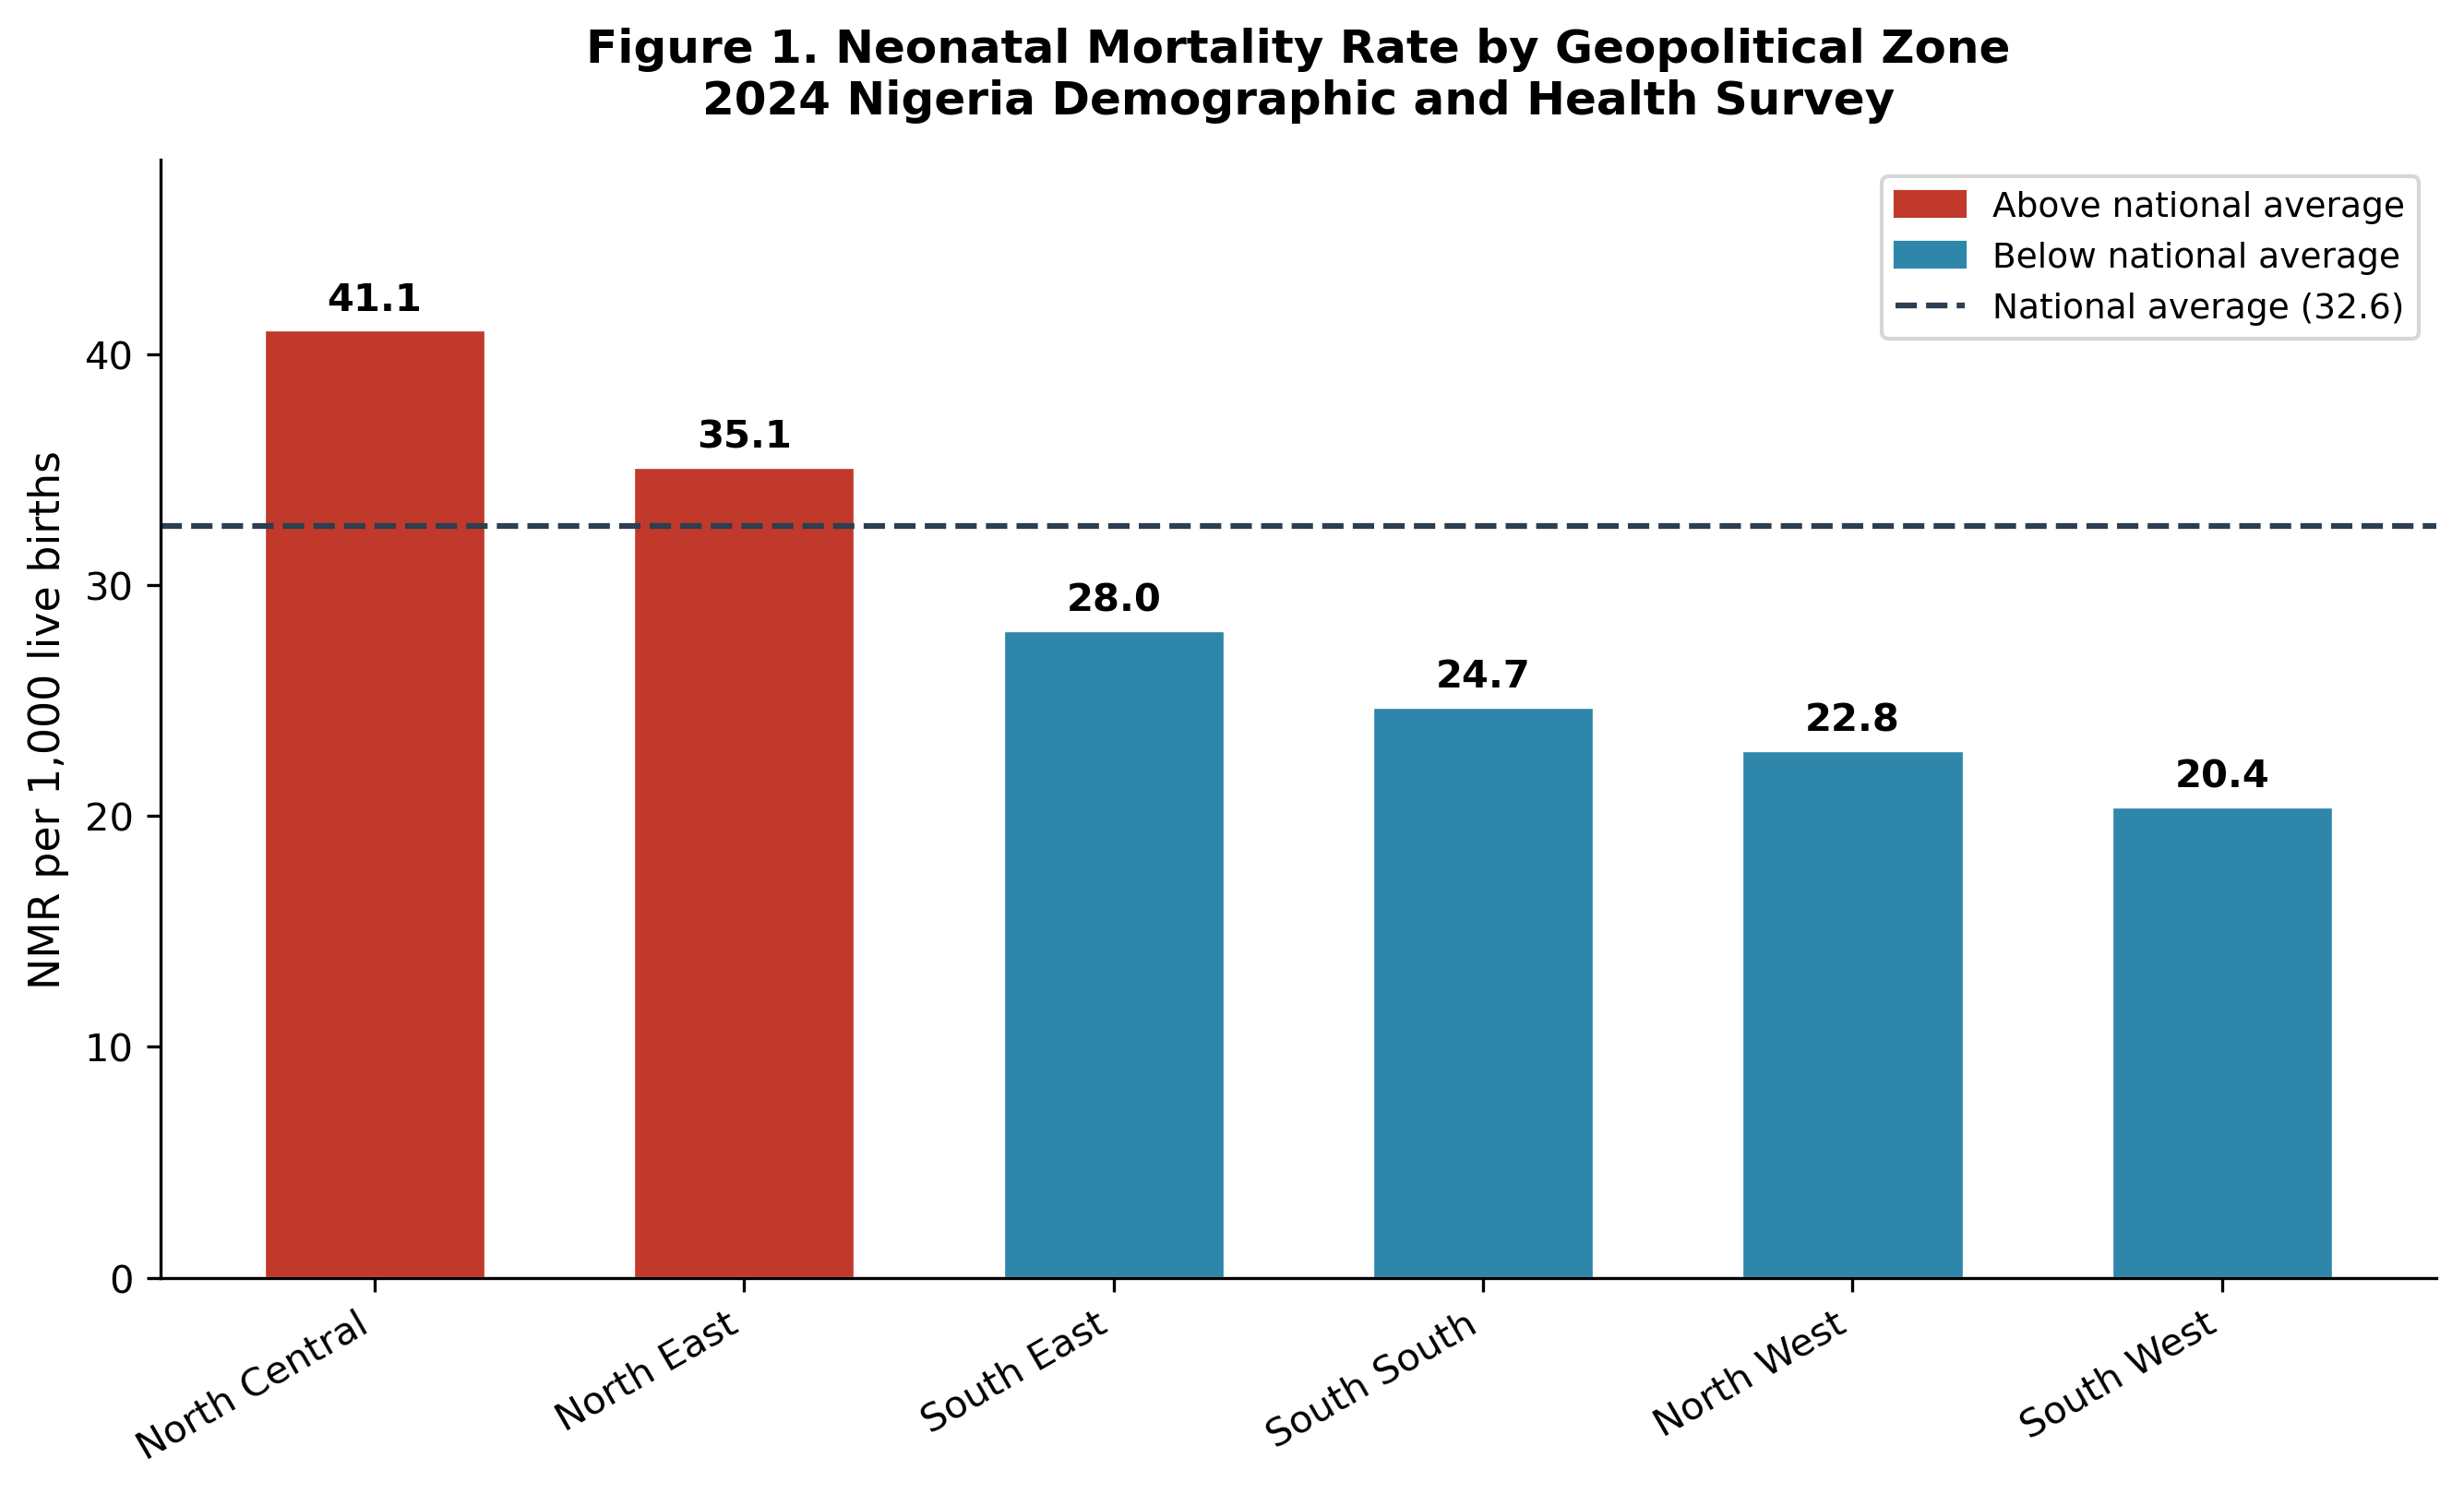

Figure 1 saved (300 dpi). National average = 32.6


In [10]:
# Figure 1: NMR bar chart by geopolitical zone.
# Red = above national average. Saved at 300 dpi as TIFF and PNG.

zone_vals = {}
for z in df_analysis['geo_zone'].cat.categories:
    sub = df_analysis[df_analysis['geo_zone'] == z]
    wd  = (sub['neonatal_death'] * sub['survey_weight']).sum()
    wb  = sub['survey_weight'].sum()
    zone_vals[z] = wd / wb * 1000 if wb > 0 else 0

wd_n    = (df_analysis['neonatal_death'] * df_analysis['survey_weight']).sum()
wb_n    = df_analysis['survey_weight'].sum()
nmr_nat = wd_n / wb_n * 1000
zs      = pd.Series(zone_vals).sort_values(ascending=False)
colours = ['#C0392B' if v > nmr_nat else '#2E86AB' for v in zs.values]

fig, ax = plt.subplots(figsize=(9, 5.5))

bars = ax.bar(range(len(zs)), zs.values, color=colours,
              edgecolor='white', linewidth=0.8, width=0.6)

ax.axhline(nmr_nat, color='#2C3E50', linewidth=1.5, linestyle='--',
           label=f'National average ({nmr_nat:.1f})')

for b, v in zip(bars, zs.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.5,
            f'{v:.1f}', ha='center', va='bottom',
            fontsize=10, fontweight='bold')

ax.set_xticks(range(len(zs)))
ax.set_xticklabels(zs.index, fontsize=10, rotation=30, ha='right')

ax.set_ylabel('NMR per 1,000 live births', fontsize=11)
ax.set_title('Figure 1. Neonatal Mortality Rate by Geopolitical Zone\n'
             '2024 Nigeria Demographic and Health Survey',
             fontsize=12, fontweight='bold', pad=12)
ax.set_ylim(0, zs.max() * 1.18)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

red_p  = mpatches.Patch(color='#C0392B', label='Above national average')
blue_p = mpatches.Patch(color='#2E86AB', label='Below national average')
ax.legend(handles=[red_p, blue_p,
    plt.Line2D([0], [0], color='#2C3E50', linewidth=1.5, linestyle='--',
               label=f'National average ({nmr_nat:.1f})')],
    loc='upper right', fontsize=9)

plt.tight_layout()
plt.savefig("Figure1_NMR_by_zone.tiff", dpi=300)
plt.savefig("Figure1_NMR_by_zone.png",  dpi=300)
plt.show()
print(f"Figure 1 saved (300 dpi). National average = {nmr_nat:.1f}")


In [12]:
# Table 4: one survey-weighted model per variable, no adjustment.
# Same complete-case sample (df_cc) as Table 5 — n is identical in both tables.

specs = [
    ('wealth',            ['Richest','Richer','Middle','Poorer','Poorest']),
    ('education',         ['Higher','Secondary','Primary','No education']),
    ('residence',         ['Urban','Rural']),
    ('geo_zone',          ['South West','South South','South East',
'North Central','North East','North West']),
    ('child_sex',         ['Female','Male']),
    ('birth_order_cat',   ['1st birth','2nd-3rd birth','4th or higher birth']),
    ('birth_interval_cat',['36+ months','24-35 months','18-23 months',
'<18 months','First birth']),
    ('maternal_age_grp',  ['15-19','20-24','25-29','30-34','35-39','40-49']),
    ('marital_status',    ['Currently married/in union','Not in union']),
]

all_rows = []
print(f"Running bivariable models... n = {len(df_cc):,}")
for var, cats in specs:
    ref     = cats[0]
    formula = f'neonatal_death ~ C({var}, Treatment("{ref}"))'
    try:
        res = run_survey_logit(formula, df_cc)
        for r in get_or_rows(res, var, cats, ref):
            all_rows.append({
'Variable': var if r['Category'].endswith('(ref)') else '',
                **r
            })
    except Exception as e:
        print(f"  WARNING {var}: {e}")

table4 = pd.DataFrame(all_rows)[['Variable','Category','OR','CI_95','p']]
print("\nTABLE 4 (Crude Odds Ratios)")
print(table4.to_string(index=False))
table4.to_csv("Table4_bivariable.csv", index=False)
print("Saved: Table4_bivariable.csv")



Running bivariable models... n = 99,271
  WARNING birth_order_cat: Error evaluating factor: NameError: name 'birth_order_cat' is not defined
    neonatal_death ~ C(birth_order_cat, Treatment("1st birth"))
                     ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^

TABLE 4 (Crude Odds Ratios)
          Variable                           Category   OR     CI_95      p
            wealth                      Richest (ref) 1.00 Reference       
                                               Richer 1.19 0.99-1.43  0.067
                                               Middle 1.25 1.03-1.52  <0.05
                                               Poorer 1.54 1.27-1.85 <0.001
                                              Poorest 1.51 1.25-1.81 <0.001
         education                       Higher (ref) 1.00 Reference       
                                            Secondary 1.28 1.02-1.60  <0.05
                                              Primary 1.31 1.03-1.67  <0.05
                  

In [13]:
# Table 5: all variables in one model simultaneously — adjusted odds ratios.
# Birth order excluded: structural overlap with birth interval.

formula_mv = (
'neonatal_death ~ '
'C(wealth,             Treatment("Richest")) + '
'C(education,          Treatment("Higher")) + '
'C(residence,          Treatment("Urban")) + '
'C(geo_zone,           Treatment("South West")) + '
'C(child_sex,          Treatment("Female")) + '
'C(birth_interval_cat, Treatment("36+ months")) + '
'C(maternal_age_grp,   Treatment("15-19")) + '
'C(marital_status,     Treatment("Currently married/in union"))'
)

print("Fitting multivariable model...")
res_mv   = run_survey_logit(formula_mv, df_cc)
res_null = run_survey_logit("neonatal_death ~ 1", df_cc)

n_obs  = len(df_cc)
lr     = -2*(res_null.llf - res_mv.llf)
r2_nag = (1-np.exp(-lr/n_obs)) / (1-np.exp(2*res_null.llf/n_obs))

print(f"  AIC            = {res_mv.aic:.2f}")
print(f"  Log-likelihood = {res_mv.llf:.2f}")
print(f"  Nagelkerke R2  = {r2_nag:.4f}")

mv_specs = [
    ('wealth',            ['Richest','Richer','Middle','Poorer','Poorest']),
    ('education',         ['Higher','Secondary','Primary','No education']),
    ('residence',         ['Urban','Rural']),
    ('geo_zone',          ['South West','South South','South East',
'North Central','North East','North West']),
    ('child_sex',         ['Female','Male']),
    ('birth_interval_cat',['36+ months','24-35 months','18-23 months',
'<18 months','First birth']),
    ('maternal_age_grp',  ['15-19','20-24','25-29','30-34','35-39','40-49']),
    ('marital_status',    ['Currently married/in union','Not in union']),
]

all_rows = []
for var, cats in mv_specs:
    ref = cats[0]
    for r in get_or_rows(res_mv, var, cats, ref):
        all_rows.append({
'Variable': var if r['Category'].endswith('(ref)') else '',
            **r
        })

table5 = pd.DataFrame(all_rows)[['Variable','Category','OR','CI_95','p']]
print("\nTABLE 5 (Adjusted Odds Ratios)")
print(table5.to_string(index=False))
print(f"\nFootnote: AIC={res_mv.aic:.2f} | LL={res_mv.llf:.2f} | Nagelkerke R2={r2_nag:.4f}")
table5.to_csv("Table5_multivariable.csv", index=False)
print("Saved: Table5_multivariable.csv")

from sklearn.metrics import roc_auc_score
y_true = df_cc['neonatal_death'].values
y_pred = res_mv.predict(df_cc)
c_stat = roc_auc_score(y_true, y_pred)
print(f"\nC-statistic (AUC) = {c_stat:.4f}")
print("Copy this value into the Table 5 footnote in the manuscript.")

Fitting multivariable model...
  AIC            = 28158.38
  Log-likelihood = -14054.19
  Nagelkerke R2  = 0.0385

TABLE 5 (Adjusted Odds Ratios)
          Variable                           Category   OR     CI_95      p
            wealth                      Richest (ref) 1.00 Reference       
                                               Richer 0.97 0.79-1.18  0.729
                                               Middle 0.84 0.68-1.03  0.098
                                               Poorer 0.91 0.70-1.18  0.469
                                              Poorest 0.83 0.63-1.09  0.178
         education                       Higher (ref) 1.00 Reference       
                                            Secondary 1.23 0.98-1.55  0.079
                                              Primary 1.18 0.92-1.53  0.193
                                         No education 1.30 1.01-1.67  <0.05
         residence                        Urban (ref) 1.00 Reference       
                  

Concentration Index = -0.0749
Negative CI = neonatal deaths concentrated among poorer households.


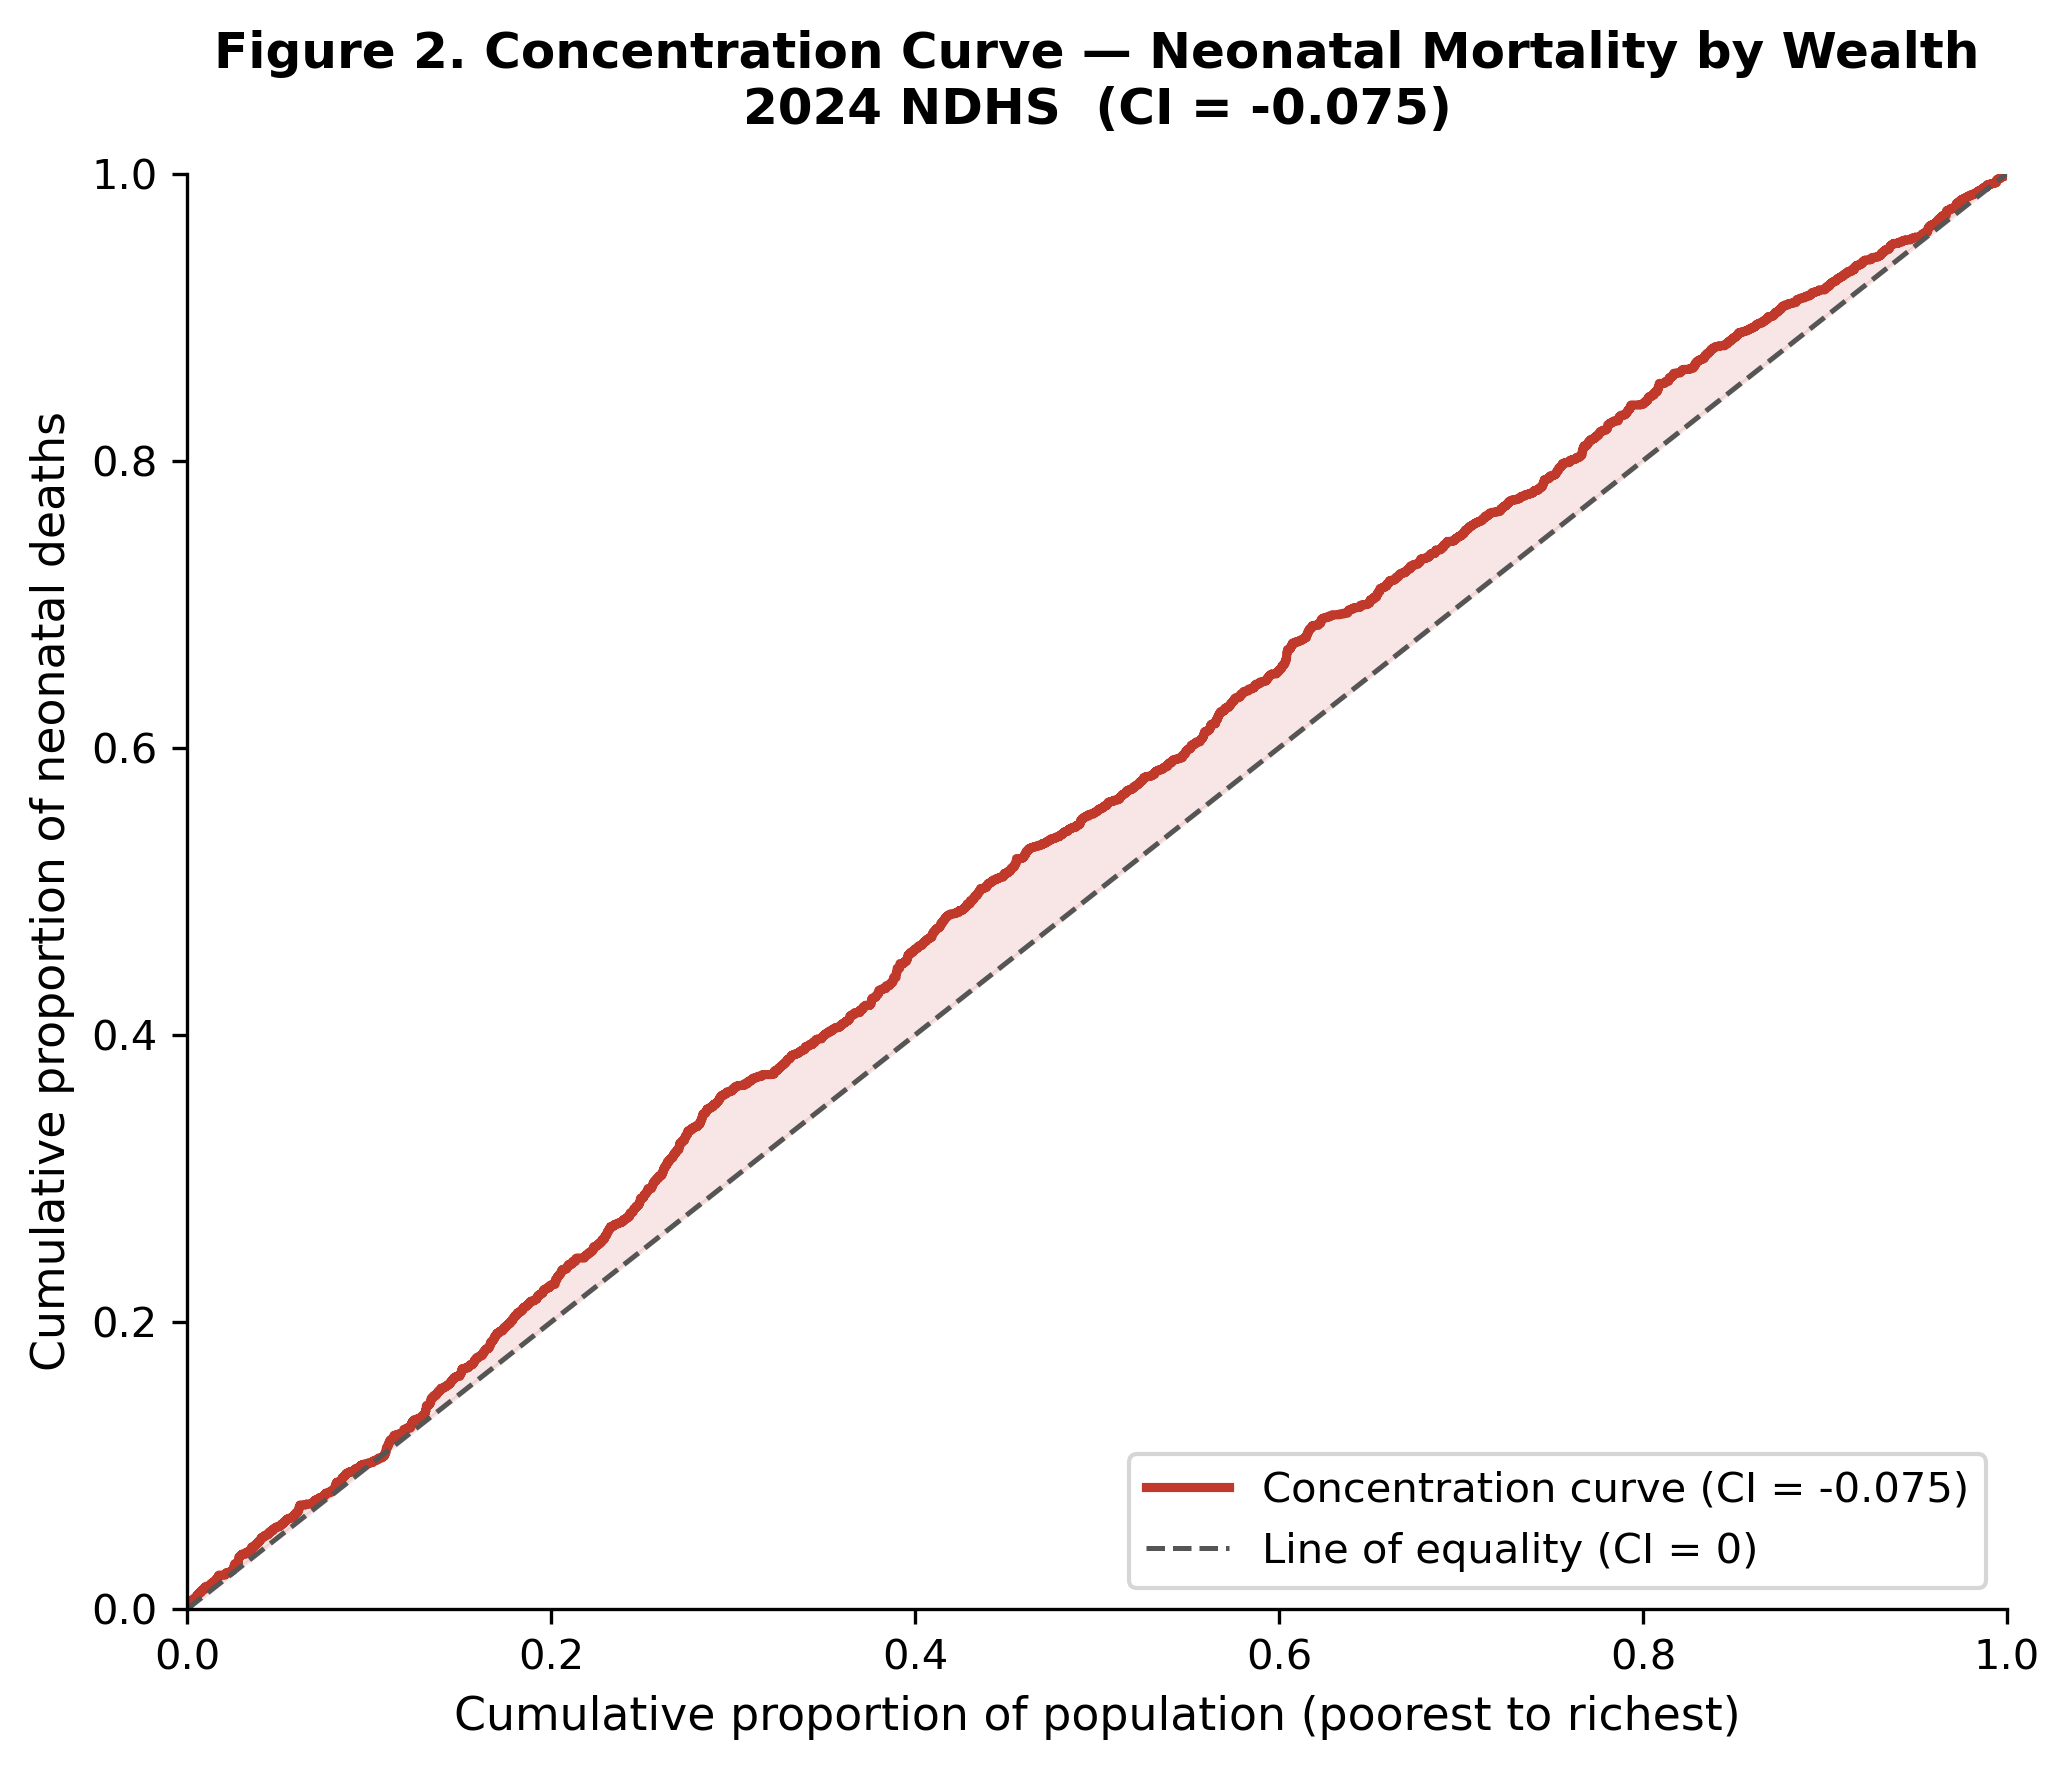

Figure 2 saved. CI = -0.0749
Concentration Index = -0.0749 (95% CI: -0.0966 to -0.0527)


In [27]:
# Figure 2: Concentration curve — neonatal deaths by household wealth.
# Curve above the diagonal = deaths concentrated among the poor.

ci_data          = df_analysis[['neonatal_death','v190','survey_weight']].dropna()
ci_data          = ci_data.sort_values('v190').copy()
n_ci             = len(ci_data)
ci_data['rfrac'] = (ci_data['v190'].rank(method='average') - 0.5) / n_ci

w  = ci_data['survey_weight'].values
h  = ci_data['neonatal_death'].values
r  = ci_data['rfrac'].values
mh = np.average(h, weights=w)
mr = np.average(r, weights=w)
CI = (2/mh) * np.average((h-mh)*(r-mr), weights=w)
print(f"Concentration Index = {CI:.4f}")
print("Negative CI = neonatal deaths concentrated among poorer households.")

ci_data['wt_d'] = ci_data['neonatal_death'] * ci_data['survey_weight']
cum_pop  = np.concatenate([[0], np.cumsum(w)/w.sum()])
cum_dead = np.concatenate([[0], np.cumsum(ci_data['wt_d'].values)/
                            ci_data['wt_d'].sum()])

fig, ax = plt.subplots(figsize=(7,6))
ax.plot(cum_pop, cum_dead, color='#C0392B', linewidth=2.2,
        label=f'Concentration curve (CI = {CI:.3f})')
ax.plot([0,1],[0,1], color='#555555', linewidth=1.2, linestyle='--',
        label='Line of equality (CI = 0)')
ax.fill_between(cum_pop, cum_dead, cum_pop, alpha=0.12, color='#C0392B')
ax.set_xlabel('Cumulative proportion of population (poorest to richest)', fontsize=11)
ax.set_ylabel('Cumulative proportion of neonatal deaths', fontsize=11)
ax.set_title(f'Figure 2. Concentration Curve — Neonatal Mortality by Wealth\n'
             f'2024 NDHS  (CI = {CI:.3f})',
             fontsize=12, fontweight='bold', pad=12)
ax.set_xlim(0,1); ax.set_ylim(0,1)
ax.legend(loc='lower right', fontsize=10)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig("Figure2_concentration_curve.tiff", dpi=300)
plt.savefig("Figure2_concentration_curve.png",  dpi=300)
plt.show()
print(f"Figure 2 saved. CI = {CI:.4f}")

# Bootstrap 95% CI for the concentration index
np.random.seed(42)
n_boot = 1000
boot_cis = []

for _ in range(n_boot):
    sample = ci_data.sample(n=len(ci_data), replace=True)
    w_b  = sample['survey_weight'].values
    h_b  = sample['neonatal_death'].values
    r_b  = sample['rfrac'].values
    mh_b = np.average(h_b, weights=w_b)
    mr_b = np.average(r_b, weights=w_b)
    ci_b = (2 / mh_b) * np.average((h_b - mh_b) * (r_b - mr_b), weights=w_b)
    boot_cis.append(ci_b)

lower = np.percentile(boot_cis, 2.5)
upper = np.percentile(boot_cis, 97.5)
print(f"Concentration Index = {CI:.4f} (95% CI: {lower:.4f} to {upper:.4f})")


In [15]:
# Final check: confirm every output file was created successfully.

outputs = [
    ("Table 1",      "Table1_sociodemographic.csv"),
    ("Table 2",      "Table2_outcome_distribution.csv"),
    ("Table 3",      "Table3_NMR_geographic.csv"),
    ("Table 4",      "Table4_bivariable.csv"),
    ("Table 5",      "Table5_multivariable.csv"),
    ("Figure 1 TIFF","Figure1_NMR_by_zone.tiff"),
    ("Figure 1 PNG", "Figure1_NMR_by_zone.png"),
    ("Figure 2 TIFF","Figure2_concentration_curve.tiff"),
    ("Figure 2 PNG", "Figure2_concentration_curve.png"),
]

print("="*58)
print("OUTPUT CHECKLIST")
print("="*58)
for label, fname in outputs:
    ok = os.path.exists(fname)
    kb = os.path.getsize(fname)/1024 if ok else 0
    print(f"  {'OK' if ok else 'MISSING':<8} {label:<18} {fname}  ({kb:.0f} KB)")

gc.collect()
print("\nMemory freed. Analysis complete.")
print("DHS auth: AuthLetter_230883 | Python 3.11 | 2024 NDHS")


OUTPUT CHECKLIST
  OK       Table 1            Table1_sociodemographic.csv  (1 KB)
  OK       Table 2            Table2_outcome_distribution.csv  (1 KB)
  OK       Table 3            Table3_NMR_geographic.csv  (0 KB)
  OK       Table 4            Table4_bivariable.csv  (1 KB)
  OK       Table 5            Table5_multivariable.csv  (1 KB)
  OK       Figure 1 TIFF      Figure1_NMR_by_zone.tiff  (16886 KB)
  OK       Figure 1 PNG       Figure1_NMR_by_zone.png  (204 KB)
  OK       Figure 2 TIFF      Figure2_concentration_curve.tiff  (14312 KB)
  OK       Figure 2 PNG       Figure2_concentration_curve.png  (210 KB)

Memory freed. Analysis complete.
DHS auth: AuthLetter_230883 | Python 3.11 | 2024 NDHS


In [28]:
# To extract exact p-values for multivariable model
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
import warnings
warnings.filterwarnings('ignore')

# Complete case sample (same as main analysis)
cols_needed = ['neonatal_death', 'wealth', 'education', 'residence',
               'geo_zone', 'child_sex', 'birth_interval_cat',
               'maternal_age_grp', 'marital_status',
               'survey_weight', 'v021']

df_model = df_analysis[cols_needed].dropna().copy()
print(f"Complete case n: {len(df_model):,}")

# Multivariable logistic regression
formula = (
    "neonatal_death ~ "
    "C(wealth,            Treatment(reference='Richest'))      + "
    "C(education,         Treatment(reference='Higher'))       + "
    "C(residence,         Treatment(reference='Urban'))        + "
    "C(geo_zone,          Treatment(reference='South West'))   + "
    "C(child_sex,         Treatment(reference='Female'))       + "
    "C(birth_interval_cat,Treatment(reference='36+ months'))   + "
    "C(maternal_age_grp,  Treatment(reference='15-19'))        + "
    "C(marital_status,    Treatment(reference='Currently married/in union'))"
)

model = smf.logit(formula=formula, data=df_model,
                  freq_weights=df_model['survey_weight'])

result_mv = model.fit(
    cov_type='cluster',
    cov_kwds={'groups': df_model['v021']},
    maxiter=300,
    disp=False
)

# Extract AOR + exact p-values
aor_table = pd.DataFrame({
    'AOR'    : np.exp(result_mv.params).round(3),
    'CI_low' : np.exp(result_mv.conf_int()[0]).round(3),
    'CI_high': np.exp(result_mv.conf_int()[1]).round(3),
    'p_value': result_mv.pvalues.round(4)
})

print("\n=== EXACT P-VALUES AND AOR — MULTIVARIABLE MODEL ===")
print(aor_table.to_string())

print(f"\nAIC        : {result_mv.aic:.2f}")
print(f"C-statistic: ", end="")

from sklearn.metrics import roc_auc_score
auc = roc_auc_score(df_model['neonatal_death'],
                    result_mv.predict())
print(f"{auc:.3f}")


Complete case n: 99,271

=== EXACT P-VALUES AND AOR — MULTIVARIABLE MODEL ===
                                                                                        AOR  CI_low  CI_high  p_value
Intercept                                                                             0.009   0.007    0.012   0.0000
C(wealth, Treatment(reference='Richest'))[T.Richer]                                   0.999   0.844    1.183   0.9916
C(wealth, Treatment(reference='Richest'))[T.Middle]                                   0.919   0.766    1.103   0.3654
C(wealth, Treatment(reference='Richest'))[T.Poorer]                                   0.953   0.773    1.176   0.6542
C(wealth, Treatment(reference='Richest'))[T.Poorest]                                  0.880   0.703    1.101   0.2635
C(education, Treatment(reference='Higher'))[T.Secondary]                              1.234   1.012    1.505   0.0374
C(education, Treatment(reference='Higher'))[T.Primary]                                1.273   1.

In [24]:
# Five-year sensitivity analysis
import pyreadstat
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
import warnings
warnings.filterwarnings('ignore')

# Step 1: Loading v008 from raw DHS file
DHS_FILE = "path/to/your/NDHS_BR_file.dta"  # Replace with actual file path

df_raw, meta = pyreadstat.read_dta(DHS_FILE,
                                    usecols=['v008', 'b3', 'v021'])
df_raw = df_raw.rename(columns={'b3': 'b3_raw'})

# Step 2: Merging v008 back into df_analysis on index 
# Both should be in the same row order from the same source file
# We merge on v021 + b3 as a safety check
df_with_v008 = df_analysis.copy()
df_with_v008 = df_with_v008.reset_index(drop=True)
df_raw       = df_raw.reset_index(drop=True)

df_with_v008['v008'] = df_raw['v008']

# Step 3: Calculate months before interview
df_with_v008['months_before_interview'] = (
    df_with_v008['v008'] - df_with_v008['b3']
)

print("Months before interview — summary:")
print(df_with_v008['months_before_interview'].describe().round(1))

# Step 4: Restrict to 5-year window
df_5yr = df_with_v008[
    df_with_v008['months_before_interview'].between(0, 60)
].copy().reset_index(drop=True)

n_full  = len(df_analysis)
n_5yr   = len(df_5yr)
nmr_5yr = df_5yr['neonatal_death'].sum() / n_5yr * 1000

print(f"\nFull sample n : {n_full:,}")
print(f"5-year sample : {n_5yr:,}  ({n_5yr/n_full*100:.1f}% retained)")
print(f"NMR (5yr)     : {nmr_5yr:.1f} per 1,000 live births")

# Step 5: Rerun exact same multivariable model on 5-year sample
cols_needed = ['neonatal_death', 'wealth', 'education', 'residence',
               'geo_zone', 'child_sex', 'birth_interval_cat',
               'maternal_age_grp', 'marital_status',
               'survey_weight', 'v021']

df_5yr_model = df_5yr[cols_needed].dropna().copy()
print(f"5-year complete case n: {len(df_5yr_model):,}")

formula = (
    "neonatal_death ~ "
    "C(wealth,            Treatment(reference='Richest'))      + "
    "C(education,         Treatment(reference='Higher'))       + "
    "C(residence,         Treatment(reference='Urban'))        + "
    "C(geo_zone,          Treatment(reference='South West'))   + "
    "C(child_sex,         Treatment(reference='Female'))       + "
    "C(birth_interval_cat,Treatment(reference='36+ months'))   + "
    "C(maternal_age_grp,  Treatment(reference='15-19'))        + "
    "C(marital_status,    Treatment(reference='Currently married/in union'))"
)

model_5yr = smf.logit(formula=formula, data=df_5yr_model,
                      freq_weights=df_5yr_model['survey_weight'])

result_5yr = model_5yr.fit(
    cov_type='cluster',
    cov_kwds={'groups': df_5yr_model['v021']},
    maxiter=300,
    disp=False
)

# Step 6: Side-by-side comparison table
# Re-run main model to get result_mv if not already available
model_main = smf.logit(formula=formula, data=df_analysis[cols_needed].dropna(),
                        freq_weights=df_analysis[cols_needed].dropna()['survey_weight'])
result_main = model_main.fit(
    cov_type='cluster',
    cov_kwds={'groups': df_analysis[cols_needed].dropna()['v021']},
    maxiter=300, disp=False
)

sens = pd.DataFrame({
    'AOR_main'  : np.exp(result_main.params).round(2),
    'p_main'    : result_main.pvalues.round(4),
    'AOR_5yr'   : np.exp(result_5yr.params).round(2),
    'p_5yr'     : result_5yr.pvalues.round(4)
})

print("\n=== SENSITIVITY TABLE: MAIN vs 5-YEAR WINDOW ===")
print(sens.to_string())
print("\nCopy this table and format it as Supplementary Table S1")

Months before interview — summary:
count    101156.0
mean        128.2
std          87.9
min          -4.0
25%          57.0
50%         114.0
75%         186.0
max         457.0
Name: months_before_interview, dtype: float64

Full sample n : 101,156
5-year sample : 26,787  (26.5% retained)
NMR (5yr)     : 34.6 per 1,000 live births
5-year complete case n: 26,419

=== SENSITIVITY TABLE: MAIN vs 5-YEAR WINDOW ===
                                                                                      AOR_main  p_main  AOR_5yr   p_5yr
Intercept                                                                                 0.01  0.0000     0.01  0.0000
C(wealth, Treatment(reference='Richest'))[T.Richer]                                       1.00  0.9916     1.05  0.7256
C(wealth, Treatment(reference='Richest'))[T.Middle]                                       0.92  0.3654     0.89  0.4502
C(wealth, Treatment(reference='Richest'))[T.Poorer]                                       0.95  0.6542   

In [25]:
# Extract exact p-values for bivariable model
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
import warnings
warnings.filterwarnings('ignore')

cols_needed = ['neonatal_death', 'wealth', 'education', 'residence',
               'geo_zone', 'child_sex', 'birth_interval_cat',
               'maternal_age_grp', 'marital_status',
               'survey_weight', 'v021']

df_biv = df_analysis[cols_needed].dropna().copy()

# Each variable run separately — that is how bivariable works
variables = {
    'wealth'            : "C(wealth,            Treatment(reference='Richest'))",
    'education'         : "C(education,         Treatment(reference='Higher'))",
    'residence'         : "C(residence,         Treatment(reference='Urban'))",
    'geo_zone'          : "C(geo_zone,          Treatment(reference='South West'))",
    'child_sex'         : "C(child_sex,         Treatment(reference='Female'))",
    'birth_interval_cat': "C(birth_interval_cat,Treatment(reference='36+ months'))",
    'maternal_age_grp'  : "C(maternal_age_grp,  Treatment(reference='15-19'))",
    'marital_status'    : "C(marital_status,    Treatment(reference='Currently married/in union'))"
}

all_results = []

for varname, formula_term in variables.items():
    formula = f"neonatal_death ~ {formula_term}"
    model = smf.logit(formula=formula, data=df_biv,
                      freq_weights=df_biv['survey_weight'])
    result = model.fit(
        cov_type='cluster',
        cov_kwds={'groups': df_biv['v021']},
        maxiter=300,
        disp=False
    )
    temp = pd.DataFrame({
        'Variable': varname,
        'COR'     : np.exp(result.params).round(3),
        'CI_low'  : np.exp(result.conf_int()[0]).round(3),
        'CI_high' : np.exp(result.conf_int()[1]).round(3),
        'p_value' : result.pvalues.round(4)
    })
    all_results.append(temp)

biv_table = pd.concat(all_results)

# Drop the intercept rows — not needed
biv_table = biv_table[~biv_table.index.str.contains('Intercept')]

print("=== EXACT P-VALUES — BIVARIABLE MODEL (Table 4) ===")
print(biv_table.to_string())

=== EXACT P-VALUES — BIVARIABLE MODEL (Table 4) ===
                                                                                                Variable    COR  CI_low  CI_high  p_value
C(wealth, Treatment(reference='Richest'))[T.Richer]                                               wealth  1.200   1.024    1.406   0.0242
C(wealth, Treatment(reference='Richest'))[T.Middle]                                               wealth  1.294   1.104    1.516   0.0014
C(wealth, Treatment(reference='Richest'))[T.Poorer]                                               wealth  1.556   1.326    1.826   0.0000
C(wealth, Treatment(reference='Richest'))[T.Poorest]                                              wealth  1.569   1.338    1.840   0.0000
C(education, Treatment(reference='Higher'))[T.Secondary]                                       education  1.293   1.072    1.560   0.0073
C(education, Treatment(reference='Higher'))[T.Primary]                                         education  1.398   1.144 